# Tutorial 15: Contributing Capacitance Data and Models

The planar capacitance models are only as good as the layouts they have seen, and every Q3D solve we run on our own designs is a layout they have not. In this tutorial, we will give our own Q3D simulations (and, if we have one, our own trained model) back to SQuADDS, so that the next designer starts from a better model. By the end of this tutorial, you will be able to: package and validate a contribution, catch broken labels with the validator, and see exactly what a pull request would add.

**Note:** this tutorial needs the optional ML extra, `pip install "squadds[ml]"`. Nothing is uploaded in this tutorial: every contribution call runs with `dry_run=True`. It builds on [Tutorial 3](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-3_Contributing_Validated_Simulation_Data_to_SQuADDS.html) (the contributor setup) and [Tutorial 14](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-14_Training_on_Your_Own_Designs.html) (training a model).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## Why contribute?

The models learned the map from a GDS layout to the full Maxwell capacitance matrix from about 45,000 Ansys Q3D simulations, each of which cost somebody minutes to an hour of solver time. A family of shapes that nobody has simulated yet is exactly where they are least reliable. If we give our simulations back:

1. the next retraining of the collective model sees our shapes, and gets better on them (and on everything that looks like them),
2. our simulations get a citable home on Hugging Face, with our name on them, and
3. nobody has to pay for the same solves again.

The catch is that a single broken label (a flipped sign, a wrong unit, two nets swapped) quietly poisons a training set. So every contribution goes through a validator first, and then through a maintainer's review.

## The story

Let's say we simulated three **concentric** capacitors in Q3D: a round island inside a ring, both inside a round pocket in the ground plane. The ring is fed by a short CPW stub from the north, and the island by one from the south, through a gap in the ring. For each design, Q3D gave us the GDS we solved, the options that generated it (JSON) and the capacitance export `cap_matrix.csv`.

For this tutorial, our three designs are real Q3D simulations from the SQuADDS planar capacitance dataset (family `exp10`, all three in its **training** split) that ship in `data/tutorial15/`. We'll see below that the validator notices they are already in the dataset.

In [2]:
import os

os.environ["QISKIT_METAL_HEADLESS"] = "1"

import warnings

warnings.filterwarnings("ignore")

In [3]:
import json
import shutil
from pathlib import Path

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

import squadds

Importing SQuADDS switches the inline figures of a notebook to PDF / SVG (a setting it inherits from scqubits), so let's switch back to PNG.

In [4]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")

We'll write everything into one folder, and start from a clean one.

In [5]:
work = Path("tutorial15_files")
shutil.rmtree(work, ignore_errors=True)
work.mkdir()

Here is what Q3D left us with: one folder per design.

In [6]:
raw = sorted(Path("data/tutorial15").iterdir())
{f.name: sorted(p.name for p in f.iterdir()) for f in raw}

{'q3d_cap_0300': ['cap_0300.gds', 'cap_0300.json', 'cap_matrix.csv'],
 'q3d_cap_0301': ['cap_0301.gds', 'cap_0301.json', 'cap_matrix.csv'],
 'q3d_cap_0302': ['cap_0302.gds', 'cap_0302.json', 'cap_matrix.csv']}

And here are the knobs we turned (µm), straight from the generator options:

In [7]:
options = {f.name: json.loads(next(f.glob("*.json")).read_text())["cap_options"] for f in raw}
knobs = ["inner_radius_x", "outer_inner_radius_x", "outer_outer_radius_x", "ground_inner_radius_x",
         "north_cpw_length", "south_cpw_length"]
pd.DataFrame({d: {k: float(o[k].replace("um", "")) for k in knobs} for d, o in options.items()}).T

,inner_radius_x,outer_inner_radius_x,outer_outer_radius_x,ground_inner_radius_x,north_cpw_length,south_cpw_length
q3d_cap_0300,91.47,119.70,135.10,171.57,25.0,30.0
q3d_cap_0301,44.13,73.28,86.95,132.29,25.0,30.0
q3d_cap_0302,90.45,103.30,122.31,145.05,25.0,20.0


## Look at the metal (and the ports) first

Before we hand anything to anybody, let's look at what we simulated. A planar capacitance contribution uses the same layer map as the models: the **ground plane on layer 1/0** and **every signal conductor on layer 1/10**. Each connected body on 1/10 is one conductor and its own net. Nets are never merged.

These GDS files also carry two tiny port stubs, on layers 2/0 (north) and 3/0 (south). Q3D used them to name the nets (`N` and `S`). The validator ignores any layer that is not in the layer map.

In [8]:
from shapely.geometry import Polygon

PORTS = {(2, 0): "north port", (3, 0): "south port"}


def plot_gds(path, names, ax):
    """Ground in grey, every conductor in its own color (labelled with its net name), port stubs in black."""
    cell = gdstk.read_gds(str(path), unit=1e-6).top_level()[0]
    k = 0
    for poly in cell.polygons:
        xy, key = poly.points, (poly.layer, poly.datatype)
        if key == (1, 0):
            ax.fill(*xy.T, color="0.82", lw=0)
        elif key == (1, 10):
            ax.fill(*xy.T, color=plt.cm.tab10.colors[k], lw=0, alpha=0.9)
            p = Polygon(xy).representative_point()
            ax.annotate(names[k], (p.x, p.y), ha="center", va="center", fontsize=11, weight="bold")
            k += 1
        elif key in PORTS:
            ax.fill(*xy.T, color="k", lw=0)
            ax.annotate(PORTS[key], xy.mean(0), xytext=(6, 0), textcoords="offset points", fontsize=8)
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
    return k

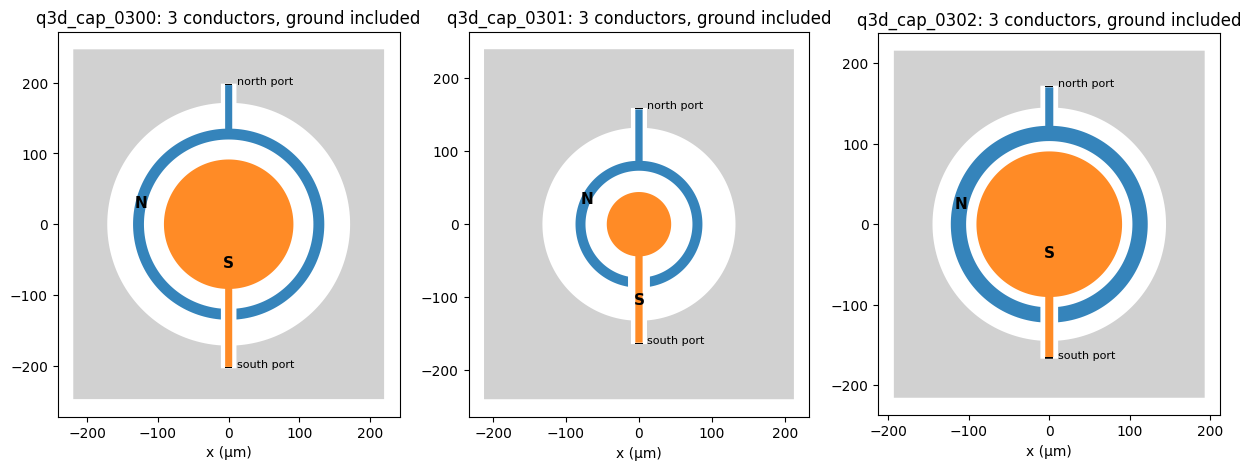

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, f in zip(axes, raw):
    n = plot_gds(next(f.glob("*.gds")), ["N", "S"], ax)
    ax.set_title(f"{f.name}: {n + 1} conductors, ground included")

Three conductors each, ground included: $N = 3$ (the ring `N`, the island `S` and the ground `G`). So each Q3D export must be a full $3 \times 3$ Maxwell matrix over `G`, `N` and `S`. The conductors on layer 1/10 come in the GDS file in the order `N`, `S`, which is the order we will declare (ground first, then the conductors in GDS file order).

## Reading the Q3D export

Q3D writes one row per adaptive pass, with one column per matrix entry, here in pF. `read_cap_matrix` from the QC module reads every pass and converts it to fF, the unit used everywhere in SQuADDS.

In [10]:
from squadds.ml.capacitance import qc

In [11]:
export = qc.read_cap_matrix(raw[0] / "cap_matrix.csv")
export["names"], export["units"], len(export["passes"])

(['G', 'N', 'S'], ['pF'], 16)

The label is the last complete pass. For $N$ conductors, the charges and voltages are related by $Q_i = \sum_j C_{ij} V_j$: the diagonal is positive (self capacitance), the off-diagonal entries are negative ($C_{ij} = -C^{\rm mutual}_{ij}$), and the matrix is symmetric.

In [12]:
last_pass, C = export["passes"][-1]
pd.DataFrame(C, index=export["names"], columns=export["names"]).round(3)

,G,N,S
G,113.847,-57.877,-34.890
N,-57.877,96.897,-35.844
S,-34.890,-35.844,74.114


It is worth a glance at how the mutual capacitances settled over the passes:

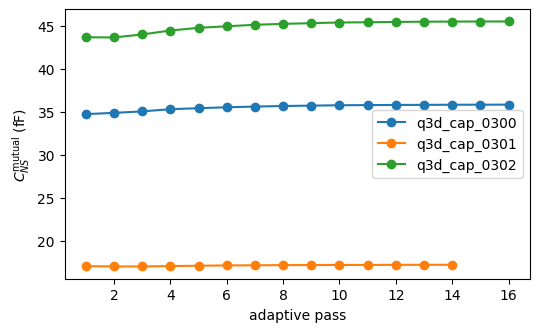

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for f in raw:
    m = qc.read_cap_matrix(f / "cap_matrix.csv")
    i, j = m["names"].index("N"), m["names"].index("S")
    ax.plot([p for p, _ in m["passes"]], [-M[i, j] for _, M in m["passes"]], "o-", label=f.name)
ax.set_xlabel("adaptive pass")
ax.set_ylabel("$C_{NS}^{\\rm mutual}$ (fF)")
ax.legend();

## Filling the contribution template

SQuADDS ships a template folder for planar capacitance contributions. Let's copy it and look inside.

In [14]:
template = Path(squadds.__file__).parent / "database" / "templates" / "planar_capacitance_contribution"
contrib = work / "my_contribution"
shutil.copytree(template, contrib)
sorted(p.name for p in contrib.iterdir())

['README.md', 'designs.csv', 'manifest.yaml']

The `README.md` in the template explains every file. In short:

```
manifest.yaml                           who, licence, solver, stack, setup, layer map, units, generator, family
designs.csv                             one row per design
gds/<design>.gds                        the solved file, as solved (not re-saved)
sims/<design>/<sim_tag>/cap_matrix.csv  the Q3D export as is (one row per adaptive pass)
```

### The manifest

The manifest says who we are, under which licence we share the data (the dataset accepts **CC-BY-4.0** or **CC0-1.0**), how we solved it and how to read it. Let's fill it in.

In [15]:
manifest = yaml.safe_load((contrib / "manifest.yaml").read_text())
manifest.update(
    org="squadds-tutorial",
    batch="2026-11-concentric",
    contributor={"name": "Jane Doe", "affiliation": "Example University", "email": "jane@example.edu",
                 "email_public": False},
    licence="CC-BY-4.0",
    family="concentric",
)

The solver, its setup, the stack and the units come straight from our Q3D project (the JSON options record the setup, and you can add the solver version when you know it). Our designs are on the standard stack: silicon ($\varepsilon_r = 11.45$), 350 µm thick, with the metal solved as a thin sheet.

In [16]:
q3d = json.loads(next(raw[0].glob("*.json")).read_text())["ansys_gds"]["q3d_signal"]["setup"]
q3d

{'AdaptiveFreq': '13GHz',
 'Cap': {'AutoIncreaseSolutionOrder': True,
  'MaxPass': 40,
  'MinConvPass': 3,
  'MinPass': 1,
  'PerError': 0.05,
  'PerRefine': 30,
  'SolutionOrder': 'Higher',
  'Solver Type': 'Iterative'},
 'Enabled': True,
 'SaveFields': True}

In [17]:
manifest["solver"] = {"name": "Ansys Q3D Extractor"}
manifest["setup"] = {"freq_GHz": 13, "PerError": q3d["Cap"]["PerError"], "MinConvPass": q3d["Cap"]["MinConvPass"],
                     "MaxPass": q3d["Cap"]["MaxPass"], "PerRefine": q3d["Cap"]["PerRefine"], "order": "high",
                     "solver_type": "iterative"}
manifest["stack"] = {"substrate_material": "silicon", "eps_r": 11.45, "substrate_um": 350,
                     "metal_model": "thin_sheet", "metal_t_um": 0.0}
manifest["layer_map"] = {"ground": [[1, 0]], "conductor": [[1, 10]]}
manifest["units"] = {"gds_unit_m": 1.0e-9, "capacitance": "pF"}
manifest["generator"] = {"name": "qiskit-metal GeneralizedCapConcentric sweep"}
manifest["description"] = ("Concentric capacitors (island + ring in a round ground pocket, north and south CPW feeds), "
                           "three Q3D solves from a radius sweep.")

In [18]:
(contrib / "manifest.yaml").write_text(yaml.safe_dump(manifest, sort_keys=False))
print((contrib / "manifest.yaml").read_text())

org: squadds-tutorial
batch: 2026-11-concentric
contributor:
  name: Jane Doe
  affiliation: Example University
  email: jane@example.edu
  email_public: false
licence: CC-BY-4.0
solver:
  name: Ansys Q3D Extractor
stack:
  substrate_material: silicon
  eps_r: 11.45
  substrate_um: 350
  metal_model: thin_sheet
  metal_t_um: 0.0
setup:
  freq_GHz: 13
  PerError: 0.05
  MinConvPass: 3
  MaxPass: 40
  PerRefine: 30
  order: high
  solver_type: iterative
layer_map:
  ground:
  - - 1
    - 0
  conductor:
  - - 1
    - 10
ground_net_name: G
units:
  gds_unit_m: 1.0e-09
  capacitance: pF
generator:
  name: qiskit-metal GeneralizedCapConcentric sweep
family: concentric
description: Concentric capacitors (island + ring in a round ground pocket, north
  and south CPW feeds), three Q3D solves from a radius sweep.
known_defects: []



### The designs, the GDS files and the simulations

Each design gets a name, its GDS under `gds/`, its Q3D export under `sims/<design>/q3d/` and one row in `designs.csv`. Here `q3d` is the *sim tag*: a second solve of the same layout, e.g. on another stack, would get its own tag. The `net_order` column is the promise we make about the matrix: `G` first, then the conductors in GDS file order.

In [19]:
rows = []
for f in raw:
    design = "concentric_" + f.name.split("_")[-1]
    (contrib / "gds").mkdir(exist_ok=True)
    shutil.copy(next(f.glob("*.gds")), contrib / "gds" / f"{design}.gds")
    sim = contrib / "sims" / design / "q3d"
    sim.mkdir(parents=True)
    shutil.copy(f / "cap_matrix.csv", sim / "cap_matrix.csv")
    params = {k: options[f.name][k] for k in knobs}
    rows.append({"design": design, "gds": f"gds/{design}.gds", "family": "concentric",
                 "params_json": json.dumps(params), "net_order": "G;N;S", "notes": "inner feed"})

In [20]:
designs = pd.DataFrame(rows)
header = [line for line in (contrib / "designs.csv").read_text().splitlines() if line.startswith("#")]
(contrib / "designs.csv").write_text("\n".join(header) + "\n" + designs.to_csv(index=False))
designs

,design,gds,family,params_json,net_order,notes
0,concentric_0300,gds/concentric_0300.gds,concentric,"{""inner_radius_x"": ""91.47um"", ""outer_inner_rad...",G;N;S,inner feed
1,concentric_0301,gds/concentric_0301.gds,concentric,"{""inner_radius_x"": ""44.13um"", ""outer_inner_rad...",G;N;S,inner feed
2,concentric_0302,gds/concentric_0302.gds,concentric,"{""inner_radius_x"": ""90.45um"", ""outer_inner_rad...",G;N;S,inner feed


Here is the folder we are about to validate:

In [21]:
sorted(p.relative_to(contrib).as_posix() for p in contrib.rglob("*") if p.is_file())

['README.md',
 'designs.csv',
 'gds/concentric_0300.gds',
 'gds/concentric_0301.gds',
 'gds/concentric_0302.gds',
 'manifest.yaml',
 'sims/concentric_0300/q3d/cap_matrix.csv',
 'sims/concentric_0301/q3d/cap_matrix.csv',
 'sims/concentric_0302/q3d/cap_matrix.csv']

## Validating the contribution

`validate_capacitance_contribution` runs the same checks the maintainers run when the pull request arrives. It **reports** instead of raising: errors block a submission, and warnings are recorded in the report for the reviewer. Per design it checks the layout, the label and duplicates. For the whole folder it checks the manifest fields, the licence, the units and the stack.

With `check_prior=True`, it also compares every label entry with `optimized_physics_prior` of the layout (a thin-film method-of-moments solve, a few seconds per layout). This physics sanity check flags entries off by more than a factor of 2.

<details>
<summary><b>The per-design checks in detail</b></summary>

- **The layout:** the GDS reads back, one top cell, the declared layers, valid polygons, and the number of conductors $N$ counted from the metal itself (it must equal the matrix size: no merged nets).
- **The label:** square over `net_order`, `G` first, symmetric, diagonal $> 0$, off-diagonal $< 0$, the signal block positive definite, the label equal to the last complete pass, and the row closure $|\sum_j C_{ij}| / C_{ii}$ (a warning above 5 %).
- **Duplicates:** the geometry hash of each layout against every design already in the dataset. A copy of a held-out **test** design is an error (it would leak a test label). A copy of any other design is a warning.

The duplicate check needs the dataset's designs table. `reference="auto"` (the default) reads it with `PlanarCapacitanceDB`, from Hugging Face or from the local copy that the environment variable `SQUADDS_PLANAR_CAP_DATA` points to.

</details>

In [22]:
from squadds.ml.capacitance.contribute import contribute_capacitance, validate_capacitance_contribution

In [23]:
report = validate_capacitance_contribution(contrib, check_prior=True, threads=2)
report

QCReport('contribution my_contribution', ok=True, errors=0, warnings=1)

No errors. Let's read the full report, exactly as the reviewer will see it in the pull request:

In [24]:
print(report.to_markdown())

# QC report: contribution my_contribution

**Result: PASS** (0 errors, 1 warnings)

## Warnings
- duplicates: exact duplicates of dataset designs (kept, same group): ["concentric_0300 = ['ref/exp10/q3d_cap_0300'] (train)", "concentric_0302 = ['ref/exp10/q3d_cap_0302'] (train)", "concentric_0301 = ['ref/exp10/q3d_cap_0301'] (train)"]

## Fixed automatically
- manifest.contributor.email removed (email_public is not true)

## Measured
- `licence`: CC-BY-4.0
- `eps_r`: 11.45
- `substrate_um`: 350
- `freq_GHz`: 13
- `training_stack`: True
- `dataset_duplicates`: 3
- `designs`: 3
- `designs_ok`: 3
- `simulations`: 3
- `family`: concentric

## concentric_0300: pass

### Measured
- `top_cells`: ['main']
- `unit_m`: 1e-09
- `precision_m`: 1e-09
- `layers`: [[1, 0], [1, 10], [2, 0], [3, 0]]
- `n_polygons`: 3
- `n_conductors`: 3
- `n_conductors_raw`: 3
- `min_gap_um`: 2
- `geom_hash`: sha256:8ed46129bcde91104f08131e08a1f62b1a0993b57e81d73b924a39e7fffee26a
- `simulations`: 1
- `net_order`: ['G', '

A few things to read in there:

- **Conductor count:** the validator counted $N = 3$ from the metal of each GDS, the same as the three nets of each matrix.
- **Label QC:** symmetric to machine precision, Maxwell signs, a positive-definite signal block, and the label is the last of the passes Q3D wrote.
- **Duplicates:** our three layouts are *exact* copies of dataset designs in the `train` split (we borrowed them, after all). With layouts of your own, this line stays empty. Had one of them been a copy of a **test** design, the report would say FAIL.
- **Stack:** the standard stack, so the label can be used by the released models directly. A different stack is accepted and recorded as off-stack.
- **Fixed automatically:** Jane's e-mail is dropped from what gets uploaded, because `email_public` is false. Absolute paths would be stripped too.

The physics sanity numbers are easier to compare in a table. For each design: the median relative difference between the Q3D mutual capacitances and the physics prior, with the MAE and RMSE in fF, and the time of the prior (with the machine and the threads it ran on).

In [25]:
cols = ["n_conductors", "closure_max_rel", "prior_median_rel_diff_pct", "prior_mae_fF", "prior_rmse_fF",
        "prior_s", "prior_threads"]
pd.DataFrame({c.subject: {k: c.info.get(k) for k in cols} for c in report.children}).T

,n_conductors,closure_max_rel,prior_median_rel_diff_pct,prior_mae_fF,prior_rmse_fF,prior_s,prior_threads
concentric_0300,3.0,0.045602,2.356024,0.939846,0.944727,39.069625,2.0
concentric_0301,3.0,0.034294,2.684088,0.587189,0.710880,6.415868,2.0
concentric_0302,3.0,0.040609,1.738719,0.929804,0.942985,10.019342,2.0


In [26]:
report.children[0].info.get("prior_machine")

'Intel(R) Xeon(R) CPU E5-2640 v4 @ 2.40GHz, 20 CPUs, Linux x86_64'

The prior is a cheap physics model, not the truth, so a few % between it and Q3D is normal. The first layout took longer because it also paid a one-time compilation of the solver. What the sanity check looks for is an entry off by a *factor*. That almost always means a unit, a sign or a net assignment went wrong somewhere. Let's break a label on purpose and see.

## Catching a broken label

### A flipped sign

Let's say our post-processing script dropped the minus sign of the `N`-`S` entry of one design (it happens more often than one would like). We make a copy of the contribution and flip it in every pass of `concentric_0301`.

In [27]:
broken = work / "broken_sign"
shutil.copytree(contrib, broken)
csv_path = broken / "sims" / "concentric_0301" / "q3d" / "cap_matrix.csv"
df = pd.read_csv(csv_path)
for col in ["C(N,S) [pF]", "C(S,N) [pF]"]:
    df[col] = -df[col]
df.to_csv(csv_path, index=False)

In [28]:
bad = validate_capacitance_contribution(broken, check_prior=True, threads=2)
bad

QCReport('contribution broken_sign', ok=False, errors=1, warnings=2)

In [29]:
print("\n".join(bad.all_errors()))

concentric_0301: sim q3d: positive off-diagonal entries (Maxwell signs need C_ij < 0): ['N-S (17.19 fF)']


Caught, and named: a positive off-diagonal entry is not a Maxwell matrix. A broken contribution cannot even be submitted, since `contribute_capacitance` validates again and refuses it.

In [30]:
try:
    contribute_capacitance(broken, dry_run=True)
except ValueError as e:
    print(e)

the contribution failed validation:
- concentric_0301: sim q3d: positive off-diagonal entries (Maxwell signs need C_ij < 0): ['N-S (17.19 fF)']


### A pF / fF mix-up

A sneakier one: the manifest says the matrices are in pF, but one of our exports was written in fF (the same numbers, 1000 times larger). Every entry is still symmetric with the right signs, so the label QC alone cannot tell. The physics sanity check can.

In [31]:
mixed = work / "broken_unit"
shutil.copytree(contrib, mixed)
csv_path = mixed / "sims" / "concentric_0302" / "q3d" / "cap_matrix.csv"
df = pd.read_csv(csv_path)
entries = [c for c in df.columns if c.startswith("C(")]
df[entries] = df[entries] * 1e3
df.to_csv(csv_path, index=False)

In [32]:
unit_check = validate_capacitance_contribution(mixed, check_prior=True, threads=2)
unit_check

QCReport('contribution broken_unit', ok=True, errors=0, warnings=2)

In [33]:
print("\n".join(w for w in unit_check.all_warnings() if "physics prior" in w))

concentric_0302: sim q3d: 6 label entries outside x0.5..x2 of the physics prior (check nets / units): ['G-G: label 1.097e+05 fF, prior 144.1 fF (x761)', 'G-N: label -5.875e+04 fF, prior -57.75 fF (x1.02e+03)', 'G-S: label -3.224e+04 fF, prior -31.16 fF (x1.03e+03)', 'N-N: label 1.071e+05 fF, prior 108.1 fF (x990)', 'N-S: label -4.553e+04 fF, prior -44.82 fF (x1.02e+03)']


Every entry of `concentric_0302` sits about a factor of 1000 away from the physics prior. This one is a **warning**, not an error. Physics sanity never rejects on its own, since a genuinely new kind of layout can disagree with a cheap prior. That is why we always read the warnings before submitting, and why a maintainer reads them again.

## What the pull request would add

Back to our clean contribution. `contribute_capacitance` validates the folder again and builds a pull request on the dataset repository `SQuADDS/SQuADDS_PlanarCapacitance`. With `dry_run=True`, it stops right before the network call and tells us exactly what it would upload.

In [34]:
plan = contribute_capacitance(contrib, check_prior=False, dry_run=True)
plan["folder"], plan["pr_url"]

('contrib/squadds-tutorial-2026-11-concentric', None)

In [35]:
plan["files"]

['contrib/squadds-tutorial-2026-11-concentric/manifest.yaml',
 'contrib/squadds-tutorial-2026-11-concentric/designs.csv',
 'contrib/squadds-tutorial-2026-11-concentric/validation_report.md',
 'contrib/squadds-tutorial-2026-11-concentric/submission.json',
 'contrib/squadds-tutorial-2026-11-concentric/gds/concentric_0300.gds',
 'contrib/squadds-tutorial-2026-11-concentric/gds/concentric_0301.gds',
 'contrib/squadds-tutorial-2026-11-concentric/gds/concentric_0302.gds',
 'contrib/squadds-tutorial-2026-11-concentric/sims/concentric_0300/q3d/cap_matrix.csv',
 'contrib/squadds-tutorial-2026-11-concentric/sims/concentric_0301/q3d/cap_matrix.csv',
 'contrib/squadds-tutorial-2026-11-concentric/sims/concentric_0302/q3d/cap_matrix.csv']

Everything lands in one folder, `contrib/<org>-<batch>/`: our manifest (sanitized), `designs.csv`, the GDS files and the simulations as we exported them, plus two files the tool writes:

- `validation_report.md`: the report we just read, so the reviewer sees the same checks
- `submission.json`: who submitted it, from the contributor block of the `.env` file at the root of SQuADDS

The `.env` contributor block is the one we set up in [Tutorial 3](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-3_Contributing_Validated_Simulation_Data_to_SQuADDS.html) (with `create_contributor_info()`), together with a Hugging Face token:

```
GROUP_NAME = "..."
PI_NAME = "..."
INSTITUTION = "..."
USER_NAME = "..."
CONTRIB_MISC = "..."
HUGGINGFACE_API_KEY = "..."
```

The token is used to open the pull request and is never written into it. Here is the submitter record on this machine (we have not filled one in, so it is mostly empty):

In [36]:
from squadds.ml.capacitance.contribute import submitter_record

submitter_record()

{'group': None,
 'PI': None,
 'institution': None,
 'uploader': None,
 'misc': None,
 'date_created': '2026-10-29 222311'}

When we are happy with the report, the real submission is the same call without `dry_run`:

```python
result = contribute_capacitance("tutorial15_files/my_contribution", check_prior=True)
result["pr_url"]  # the pull request on huggingface.co/datasets/SQuADDS/SQuADDS_PlanarCapacitance
```

It opens a **pull request** and nothing more. Nothing is merged until a maintainer has reviewed it. After the merge, the maintainers compute the physics priors and the embeddings of our layouts on their cluster, so that every row of the dataset is computed the same way. They add them to the dataset with `source = "community"` and `split = "none"`: community data is used for training and never becomes part of the held-out test set.

## Contributing a model

Now the other half. Let's say we followed [Tutorial 14](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-14_Training_on_Your_Own_Designs.html), trained a model and pushed its checkpoints to a model repository of our own on Hugging Face. SQuADDS keeps a **model zoo**: a `model_zoo.yaml` file in the dataset repository that lists contributed models next to the released ones. Each is pinned to an exact revision with the sha256 of every checkpoint.

A model repository for the zoo holds the `*.pt` checkpoints (the run folders of `squadds-ml train`) and a `squadds_model.yaml` file that answers four questions:

1. **Who made it, and under which licence?** (`name`, `title`, `licence`, `contributor`)
2. **What was it trained on?** (`training_data`: the sha256 of the training shards and the split used: `train`, `train+val`, `all` or `custom`)
3. **How good is it?** (`val_score`: the median % error on the **validation** split, always with the MAE and RMSE in fF, and the number of layouts)
4. **How fast is it?** (the time per layout, with the machine and the number of threads it was measured on)

### Our model

So that this tutorial does not have to train anything, we stand in for our own model with one whose answers we know: the released `QCap` model. `load_model` gives us a verified local copy.

In [37]:
from squadds.ml.capacitance import load_model

qcap = load_model("QCap")
qcap.repo_id, qcap.revision, qcap.title

('SQuADDS/QCap',
 '25bdbb19ea3a17b2e86b08baea7b320e2d06d3a0',
 'QCap (~1 s): extrapolated physics R(1.5, 3) on the corrected prior + residual networks, compiled solver')

We put its checkpoints into a folder of our own, laid out like a model repository:

In [38]:
my_model = work / "my_model"
(my_model / "qcap").mkdir(parents=True)
for pt in sorted((qcap.root / "qcap").glob("*.pt")):
    (my_model / "qcap" / pt.name).symlink_to(pt.resolve())
sorted(p.relative_to(my_model).as_posix() for p in my_model.rglob("*.pt"))

['qcap/acc_v2m_sf_s0.pt',
 'qcap/acc_v2m_sf_s1.pt',
 'qcap/acc_v2m_sf_s2.pt']

The training data hash pins the exact data the model saw. Checkpoints written by the SQuADDS trainer record the sha256 of every training shard (`data_sha`), so we hash that map:

In [39]:
import hashlib

import torch

data_sha = torch.load(my_model / "accurate" / "acc_v2m_sf_s0.pt", map_location="cpu", weights_only=False)["data_sha"]
training_sha = hashlib.sha256(json.dumps(data_sha, sort_keys=True).encode()).hexdigest()
training_sha

'671583ead040bc0bad0ff8ed085a0a2c965579e42dfe38b382426f28e256bba8'

Now the metadata. `QCap` was trained on all the data, so it has no validation score of its own: we report its one never-seen check instead (B5, 39 layouts that no part of the model saw) and the time per layout from its model card:

In [40]:
meta = {
    "name": "tutorial15-qcap-copy",
    "title": "Tutorial 15 stand-in: QCap's checkpoints",
    "licence": "MIT",
    "base": {"name": "QCap"},
    "contributor": {"name": "Jane Doe", "affiliation": "Example University"},
    "training_data": {"sha256": training_sha, "split_used": "all",
                      "description": "all 45,771 on-stack layouts of the SQuADDS planar capacitance dataset"},
    "val_score": {"median_pct": 1.05, "mae_fF": 0.132, "rmse_fF": 0.188, "layouts": 39, "split": "B5 (never seen)",
                  "seconds_per_layout": 0.845, "machine": "x86_64 cluster node", "threads": 2,
                  "note": "from the model card (B5 check); time = median prediction time per layout"},
}

We write it next to the checkpoints, and our model repository is ready:

In [41]:
(my_model / "squadds_model.yaml").write_text(yaml.safe_dump(meta, sort_keys=False))
sorted(p.relative_to(my_model).as_posix() for p in my_model.rglob("*") if p.is_file())

['qcap/acc_v2m_sf_s0.pt',
 'qcap/acc_v2m_sf_s1.pt',
 'qcap/acc_v2m_sf_s2.pt',
 'squadds_model.yaml']

`base: {name: QCap}` tells the validator that these checkpoints use the architecture of a released model, so it loads them with `load_model("QCap", path=...)`. For run folders from `squadds-ml train`, leave `base` out.

### Validating the model

`validate_model` checks that the metadata is complete, takes the sha256 of every checkpoint, **loads** the checkpoints, and builds the entry for the zoo. With `local_dir`, it works on a local copy and needs no download. The real call resolves the revision of the Hugging Face repository to a full commit sha.

In [42]:
from squadds.ml.capacitance.contribute import contribute_model, validate_model

In [43]:
model_report, entry = validate_model(qcap.repo_id, qcap.revision, local_dir=my_model)
model_report

QCReport('model SQuADDS/QCap@25bdbb19ea3a17b2e86b08baea7b320e2d06d3a0', ok=True, errors=0, warnings=2)

In [44]:
print(model_report.to_markdown())

# QC report: model SQuADDS/QCap@25bdbb19ea3a17b2e86b08baea7b320e2d06d3a0

**Result: PASS** (0 errors, 2 warnings)

## Warnings
- trained on test layouts: the model is listed without any test score (not eligible for maintainer scoring)
- validation score self-reported (pass val_data to compute it here)

## Measured
- `arm`: full_gnn
- `files`: 3
- `val_median_pct`: 1.05
- `val_mae_fF`: 0.132



It passes, with two warnings: the model was trained on test layouts, and the validation score is *self-reported*. Passing `val_data=` (a validation shard folder) makes `validate_model` score the model itself with `benchmark.score` and replace the self-reported numbers. Here is the zoo entry it built:

In [45]:
print(yaml.safe_dump(entry, sort_keys=False))

id: tutorial15-qcap-copy
repo_id: SQuADDS/QCap
revision: 25bdbb19ea3a17b2e86b08baea7b320e2d06d3a0
title: 'Tutorial 15 stand-in: QCap''s checkpoints'
arm: full_gnn
base:
  name: QCap
licence: MIT
contributor:
  name: Jane Doe
  affiliation: Example University
files:
- path: qcap/acc_v2m_sf_s0.pt
  sha256: cc69c5818f5028c26177159b88239116520abbb290743d6a6c091657e8dbf1c5
- path: qcap/acc_v2m_sf_s1.pt
  sha256: 2f88606dbec5c599550d088213a4c37af3b3ad5134ebad2e60519fb534553a57
- path: qcap/acc_v2m_sf_s2.pt
  sha256: d13bafc6b2eb7cadcd97a387d791c0210976db1a9d618f9acc1b614e3701daed
training_data:
  sha256: 671583ead040bc0bad0ff8ed085a0a2c965579e42dfe38b382426f28e256bba8
  split_used: all
  description: all 45,771 on-stack layouts of the SQuADDS planar capacitance dataset
val_score:
  median_pct: 1.05
  mae_fF: 0.132
  rmse_fF: 0.188
  layouts: 39
  split: B5 (never seen)
  seconds_per_layout: 0.845
  machine: x86_64 cluster node
  threads: 2
  note: from the model card (B5 check); time = media

Note `test_eligible: false`: the model was trained on all the data, test layouts included, so it is listed without any test score. Such a model can still be the best one to *use*, it just cannot be benchmarked on the test set.

### Why test scores are maintainer-run, once

The held-out test set is the only number that says how good a model is on layouts nobody tuned anything on. That only stays true if nobody looks at it while developing. Every time we score on the test set and then change something, the test set quietly becomes part of our validation set. So:

- the zoo takes a **validation** score from us, never a test score
- the maintainers score each declared model on the test set **once**, and only if it was trained on the TRAIN split (a model that saw test layouts during training cannot have an honest test score at all)

Let's check that the validator enforces both. First, a test score passed off as a validation score:

In [46]:
cheat = {**meta, "val_score": {**meta["val_score"], "split": "test"}}
rep, _ = validate_model(qcap.repo_id, qcap.revision, local_dir=my_model, metadata=cheat)
rep.ok, rep.all_errors()

(False,
 ['val_score is a test score: test scores are maintainer-run only, report the validation split'])

And the same checkpoints declared as trained on the TRAIN split only, as a model of our own trained on `train` would be:

In [47]:
train_only = {**meta, "training_data": {**meta["training_data"], "split_used": "train"}}
rep, e = validate_model(qcap.repo_id, qcap.revision, local_dir=my_model, metadata=train_only)
rep.ok, e["test_eligible"], [w for w in rep.all_warnings() if "test" in w]

(True, True, [])

Accepted, and eligible for one maintainer-run test score. The validator cannot check `split_used` against the checkpoints, so the maintainers also check the training keys a checkpoint records against the test layouts before they score it.

### What the model pull request would add

`contribute_model` runs the same validation and builds a pull request that adds our entry to `model_zoo.yaml` and our validation report next to it. With `dry_run=True` and a `local_dir`, nothing touches the network:

In [48]:
model_plan = contribute_model(qcap.repo_id, qcap.revision, local_dir=my_model, dry_run=True)
model_plan["files"], model_plan["pr_url"]

(['model_zoo.yaml', 'model_zoo/tutorial15-qcap-copy/validation_report.md'],
 None)

For a model of our own, the real call points at our Hugging Face model repository and its revision (the checkpoints are downloaded and verified again, and a duplicate `repo@revision` is refused):

```python
result = contribute_model("my-lab/my-capacitance-model", revision="main")
result["pr_url"]  # a pull request adding the entry to model_zoo.yaml
```

Like the data, it is a pull request that the maintainers review before anything is listed.

Thank you a BUNCH for your interest in contributing to SQuADDS!!! 

## Next Steps...

The [ML Models](https://lfl-lab.github.io/SQuADDS/source/ml_models.html) page collects everything about the planar capacitance models: the released models, their accuracy and time, the dataset and how contributions are reviewed. If you also have simulation data for the other SQuADDS components (qubits, cavities, couplers), [Tutorial 3](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-3_Contributing_Validated_Simulation_Data_to_SQuADDS.html) shows how to contribute it to the SQuADDS database.

## License

<div style='width: 100%; background-color:#3cb1c2;color:#324344;padding-left: 10px; padding-bottom: 10px; padding-right: 10px; padding-top: 5px'>
    <h3>This code is a part of SQuADDS</h3>
    <p>Developed by Sadman Ahmed Shanto</p>
    <p>This tutorial is written by Sadman Ahmed Shanto and Claude Opus 5.5</p>
    <p>&copy; Copyright Sadman Ahmed Shanto & Eli Levenson-Falk 2026.</p>
    <p>This code is licensed under the MIT License. You may<br> obtain a copy of this license in the LICENSE.txt file in the root directory<br> of this source tree.</p>
    <p>Any modifications or derivative works of this code must retain this<br>copyright notice, and modified files need to carry a notice indicating<br>that they have been altered from the originals.</p>
</div>